# Phase 2: Feature Engineering

Brief overview: building the team-season feature table that all models 
will train on, combining standings, Four Factors, Net Rating, MVP shares, 
All-NBA presence, and playoff-derived features across the 2024-25 and 
2025-26 seasons.

## 1. Imports

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
from itertools import groupby
from nba_api.stats.endpoints import commonteamroster
from nba_api.stats.static import teams
from nba_api.stats.endpoints import leaguegamefinder
from nba_api.stats.endpoints import leaguedashplayerstats
import time
import re

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
SNAPSHOT_TAG = 'opening_week_oct2026'  # e.g., change to 'trade_deadline_feb2027' for a new checkpoint
REFRESH_API = False                     # set True (or use a new SNAPSHOT_TAG) to pull live from nba_api

ROSTER_CACHE_PATH = PROJECT_ROOT / 'data' / 'raw' / f'rosters_26_27_{SNAPSHOT_TAG}.csv'
PLAYER_PLAYOFF_CACHE_PATH = PROJECT_ROOT / 'data' / 'raw' / 'player_playoff_games_24_26.csv'
PLAYER_REGULAR_CACHE_PATH = PROJECT_ROOT / 'data' / 'raw' / 'player_regular_games_24_26.csv'

## 2. Load Cleaned Game Data

**Question:** What does our Phase 1 output look like once loaded fresh 
into this notebook, and is it ready to aggregate?

We load the cleaned game-level dataset produced in Phase 1 
(`01_data_extraction.ipynb`) as the foundation for all features built 
in this notebook.

In [2]:
# read in the cleaned games data
games_combined = pd.read_csv(PROJECT_ROOT / 'data' / 'processed' / 'games_clean.csv', dtype={'GAME_ID': str})

# shape and preview the data
display(games_combined.shape)
display(games_combined.head())

(5258, 30)

,SEASON_ID,TEAM_ID,TEAM_ABBREVIATION,TEAM_NAME,GAME_ID,GAME_DATE,MATCHUP,WL,MIN,PTS,...,DREB,REB,AST,STL,BLK,TOV,PF,PLUS_MINUS,SEASON_LABEL,SEASON_TYPE_LABEL
0,22024,1610612746,LAC,LA Clippers,0022401198,2025-04-13,LAC @ GSW,W,265,124,...,33,42,28,11,3,16,21,5.0,2024-25,Regular Season
1,22024,1610612741,CHI,Chicago Bulls,0022401191,2025-04-13,CHI @ PHI,W,240,122,...,44,59,29,10,4,12,17,20.0,2024-25,Regular Season
2,22024,1610612754,IND,Indiana Pacers,0022401189,2025-04-13,IND @ CLE,W,289,126,...,47,61,27,15,10,13,20,8.0,2024-25,Regular Season
3,22024,1610612758,SAC,Sacramento Kings,0022401200,2025-04-13,SAC vs. PHX,W,243,109,...,33,43,31,6,4,11,7,11.0,2024-25,Regular Season
4,22024,1610612763,MEM,Memphis Grizzlies,0022401194,2025-04-13,MEM vs. DAL,W,239,132,...,34,53,31,13,7,11,15,35.0,2024-25,Regular Season


**Takeaway:** 

The dataset consists of 5,258 rows and 30 columns, representing a complete historical record of the 2024-25 and 2025-26 NBA seasons.The row count is the exact mathematical sum of all games played across both seasons, encompassing both regular season and postseason play. A count of 2,460 matches the exact schedule capacity for a standard NBA regular season where 30 teams play 82 games each.

| Season     | Season Type    | Game Count |
| ---------- | -------------- | ---------- |
| 2024-25    | Regular Season | 2,460      |
| 2024-25    | Playoffs       | 168        |
| 2025-26    | Regular Season | 2,460      |
| 2025-26    | Playoffs       | 170        |
| Total Rows |                | 5,258      |


## 3. Team-Season Standings Aggregation

**Question:** What does each team's season look like when reduced to 
one row — wins, losses, and win percentage?

This becomes the base table every other feature in this notebook joins onto.

In [3]:
# filtering games_combined to only Regular Season rows (SEASON_TYPE_LABEL = 'Regular Season')
games_regular_season = games_combined[games_combined['SEASON_TYPE_LABEL'] == 'Regular Season'].copy()

# creating a WIN column from the WL column
games_regular_season['WIN'] = games_regular_season['WL'].apply(lambda x: 1 if x == 'W' else 0)

# grouping SEASON_LABEL and TEAM_ABBREVIATION, aggregating the total wins (sum of WIN), total games played (count), win percentage (wins / games played)
games_regular_season_grouped = games_regular_season.groupby(['SEASON_LABEL', 'TEAM_ABBREVIATION']).agg({
    'WIN': 'sum',
    'GAME_ID': 'count'
}).reset_index()

# calculating win percentage
games_regular_season_grouped['WIN_PERCENTAGE'] = games_regular_season_grouped['WIN'] / games_regular_season_grouped['GAME_ID']

# preview the grouped data (should be 30 teams x 2 seasons = 60 rows)
display(games_regular_season_grouped.shape)
display(games_regular_season_grouped.head())

(60, 5)

,SEASON_LABEL,TEAM_ABBREVIATION,WIN,GAME_ID,WIN_PERCENTAGE
0,2024-25,ATL,40,82,0.487805
1,2024-25,BKN,26,82,0.317073
2,2024-25,BOS,61,82,0.743902
3,2024-25,CHA,19,82,0.231707
4,2024-25,CHI,39,82,0.475610


**Takeaway:** Aggregating regular season games to team-level yields 60 
rows — 30 teams across 2 seasons — confirming complete coverage with no 
missing or duplicated teams. This table now serves as the base for every 
other feature joined in this notebook.

## 4. Opponent Join

**Question:** How do we get each team's own stats and their opponent's 
stats on the same row, which both Net Rating and precise Four Factors 
require?

Each game currently appears as two separate rows (one per team) sharing 
the same GAME_ID. Self-joining on GAME_ID lets us attach the opponent's 
stat line to each team's row.

In [4]:
# create a copy of games_regular_season with columns renamed to have an "OPP_" prefix for the opponent team stats, keeping game_id and team_abbreviation as is for now
games_regular_season_opp = games_regular_season.copy()
games_regular_season_opp = games_regular_season_opp.rename(columns={
    col: f"OPP_{col}" for col in games_regular_season_opp.columns if col not in ['GAME_ID']
})

# merge games_regular_season with this renamed copy, on GAME_ID
games_regular_season_merged = pd.merge(
    games_regular_season, 
    games_regular_season_opp, 
    on='GAME_ID', 
    how='left', 
)

#  dropping rows where a team got merged with itself as its own opponent
games_regular_season_merged = games_regular_season_merged[
    games_regular_season_merged['TEAM_ABBREVIATION'] != games_regular_season_merged['OPP_TEAM_ABBREVIATION']
]

print("Shape of the merged dataframe:")
display(games_regular_season_merged.shape)

Shape of the merged dataframe:


(4920, 61)

## 5. Four Factors

**Question:** Beyond win percentage, what do the underlying shooting, 
turnover, rebounding, and free-throw tendencies tell us about each 
team's style and efficiency?

The Four Factors (eFG%, TOV%, ORB%, FT Rate) are a standard basketball 
analytics framework for isolating what actually wins games, weighted 
roughly in that priority order.

In [5]:
# on games_regular_season, calculate each four factor at the game-row level first (per team, per game)
games_regular_season_merged['eFG%'] = (games_regular_season_merged['FGM'] + 0.5 * games_regular_season_merged['FG3M']) / games_regular_season_merged['FGA']
games_regular_season_merged['TOV%'] = games_regular_season_merged['TOV'] / (games_regular_season_merged['FGA'] + 0.44 * games_regular_season_merged['FTA'] + games_regular_season_merged['TOV'])
games_regular_season_merged['ORB%'] = games_regular_season_merged['OREB'] / (games_regular_season_merged['OREB'] + games_regular_season_merged['OPP_DREB'])
games_regular_season_merged['FT Rate'] = games_regular_season_merged['FTM'] / games_regular_season_merged['FGA']
print("Shape of the merged dataframe with four factors:")
display(games_regular_season_merged.head())

# groupby SEASON_LABEL and TEAM_ABBREVIATION, taking the mean of each four factor across the season
games_4_factors = games_regular_season_merged.groupby(['SEASON_LABEL', 'TEAM_ABBREVIATION']).agg({
    'eFG%': 'mean',
    'TOV%': 'mean',
    'ORB%': 'mean',
    'FT Rate': 'mean'
}).reset_index()
print("Shape of the four factors dataframe:")
display(games_4_factors.head())

# merging this back onto games_regular_season_grouped, joingin on SEASON_LABEL and TEAM_ABBREVIATION
games_regular_season_grouped = pd.merge(
    games_regular_season_grouped, 
    games_4_factors, 
    on=['SEASON_LABEL', 'TEAM_ABBREVIATION'], 
    how='left'
    )
print("Shape of the grouped dataframe with four factors:")
display(games_regular_season_grouped.head())

Shape of the merged dataframe with four factors:


,SEASON_ID,TEAM_ID,TEAM_ABBREVIATION,TEAM_NAME,GAME_ID,GAME_DATE,MATCHUP,WL,MIN,PTS,...,OPP_TOV,OPP_PF,OPP_PLUS_MINUS,OPP_SEASON_LABEL,OPP_SEASON_TYPE_LABEL,OPP_WIN,eFG%,TOV%,ORB%,FT Rate
1,22024,1610612746,LAC,LA Clippers,0022401198,2025-04-13,LAC @ GSW,W,265,124,...,15,20,-5.0,2024-25,Regular Season,0,0.639535,0.145560,0.290323,0.162791
3,22024,1610612741,CHI,Chicago Bulls,0022401191,2025-04-13,CHI @ PHI,W,240,122,...,14,15,-20.0,2024-25,Regular Season,0,0.519417,0.096931,0.283019,0.145631
5,22024,1610612754,IND,Indiana Pacers,0022401189,2025-04-13,IND @ CLE,W,289,126,...,21,23,-8.0,2024-25,Regular Season,0,0.445378,0.091756,0.229508,0.168067
7,22024,1610612758,SAC,Sacramento Kings,0022401200,2025-04-13,SAC vs. PHX,W,243,109,...,11,9,-11.0,2024-25,Regular Season,0,0.602273,0.109649,0.263158,0.034091
9,22024,1610612763,MEM,Memphis Grizzlies,0022401194,2025-04-13,MEM vs. DAL,W,239,132,...,18,13,-35.0,2024-25,Regular Season,0,0.572115,0.090461,0.404255,0.125000


Shape of the four factors dataframe:


,SEASON_LABEL,TEAM_ABBREVIATION,eFG%,TOV%,ORB%,FT Rate
0,2024-25,ATL,0.547733,0.126258,0.260635,0.198276
1,2024-25,BKN,0.517414,0.127060,0.242355,0.190842
2,2024-25,BOS,0.561858,0.103155,0.255842,0.170975
3,2024-25,CHA,0.503948,0.132114,0.264301,0.175867
4,2024-25,CHI,0.554492,0.121329,0.222886,0.175299


Shape of the grouped dataframe with four factors:


,SEASON_LABEL,TEAM_ABBREVIATION,WIN,GAME_ID,WIN_PERCENTAGE,eFG%,TOV%,ORB%,FT Rate
0,2024-25,ATL,40,82,0.487805,0.547733,0.126258,0.260635,0.198276
1,2024-25,BKN,26,82,0.317073,0.517414,0.127060,0.242355,0.190842
2,2024-25,BOS,61,82,0.743902,0.561858,0.103155,0.255842,0.170975
3,2024-25,CHA,19,82,0.231707,0.503948,0.132114,0.264301,0.175867
4,2024-25,CHI,39,82,0.475610,0.554492,0.121329,0.222886,0.175299


**Takeaway:** Four Factor values fall within expected ranges across all 
teams (eFG% roughly 0.50–0.56, TOV%/ORB%/FT Rate all reasonable 
decimals), confirming the opponent join and calculations are working 
correctly.

## 6. Net Rating

**Question:** How much better or worse is each team than their 
opponents, on a scale that's fair regardless of pace (fast vs. slow 
teams)?

Net Rating is a standard basketball analytics measure — point 
differential per 100 possessions — that's a stronger signal of true 
team strength than raw win percentage alone.

In [6]:
# estimating possessions per game (formula: FGA - OREB + TOV + 0.44 * FTA)
games_regular_season_merged['POSS'] = games_regular_season_merged['FGA'] - games_regular_season_merged['OREB'] + games_regular_season_merged['TOV'] + 0.44 * games_regular_season_merged['FTA']

# calculating per-game Net Rating (formula: (PTS - OPP_PTS) / POSS * 100)
games_regular_season_merged['NET_RATING'] = (games_regular_season_merged['PTS'] - games_regular_season_merged['OPP_PTS']) / games_regular_season_merged['POSS'] * 100

# grouping by SEASON_LABEL and TEAM_ABBREVIATION, taking the mean of NET_RATING across the season
games_net_rating = games_regular_season_merged.groupby(['SEASON_LABEL', 'TEAM_ABBREVIATION']).agg({
    'NET_RATING': 'mean'
}).reset_index()
print("Shape of the net rating dataframe:", games_net_rating.shape)
display(games_net_rating.head())

# merging onto games_regular_season_grouped, joining on SEASON_LABEL and TEAM_ABBREVIATION
games_regular_season_grouped = pd.merge(
    games_regular_season_grouped, 
    games_net_rating,
    on=['SEASON_LABEL', 'TEAM_ABBREVIATION'],
    how='left'
)
print("Shape of the grouped dataframe with four factors and net rating:", games_regular_season_grouped.shape)
display(games_regular_season_grouped.head(10))

Shape of the net rating dataframe: (60, 3)


,SEASON_LABEL,TEAM_ABBREVIATION,NET_RATING
0,2024-25,ATL,-0.958159
1,2024-25,BKN,-7.125251
2,2024-25,BOS,9.397202
3,2024-25,CHA,-9.050762
4,2024-25,CHI,-1.438779


Shape of the grouped dataframe with four factors and net rating: (60, 10)


,SEASON_LABEL,TEAM_ABBREVIATION,WIN,GAME_ID,WIN_PERCENTAGE,eFG%,TOV%,ORB%,FT Rate,NET_RATING
0,2024-25,ATL,40,82,0.487805,0.547733,0.126258,0.260635,0.198276,-0.958159
1,2024-25,BKN,26,82,0.317073,0.517414,0.127060,0.242355,0.190842,-7.125251
2,2024-25,BOS,61,82,0.743902,0.561858,0.103155,0.255842,0.170975,9.397202
3,2024-25,CHA,19,82,0.231707,0.503948,0.132114,0.264301,0.175867,-9.050762
4,2024-25,CHI,39,82,0.475610,0.554492,0.121329,0.222886,0.175299,-1.438779
5,2024-25,CLE,64,82,0.780488,0.578973,0.110769,0.258348,0.189829,9.442753
6,2024-25,DAL,39,82,0.475610,0.550836,0.119703,0.234250,0.205392,-1.107044
7,2024-25,DEN,50,82,0.609756,0.574615,0.119232,0.266557,0.202515,3.758321
8,2024-25,DET,44,82,0.536585,0.548781,0.124178,0.259457,0.194834,1.934339
9,2024-25,GSW,48,82,0.585366,0.537070,0.116519,0.271509,0.189377,3.262096


**Takeaway:** Net Rating values fall within the expected -10 to +10 
range, with top-performing teams (e.g. Boston in 2024-25) landing 
clearly positive and bottom teams clearly negative — confirming the 
possession estimate and point differential calculation are directionally 
correct.

### 6b. Exploratory Visualization: Four Factors Correlation Heatmap

We evaluate the pairwise correlation between Dean Oliver's Four Factors, pace-adjusted Net Rating, and regular-season winning percentage across all 60 historical team-seasons.

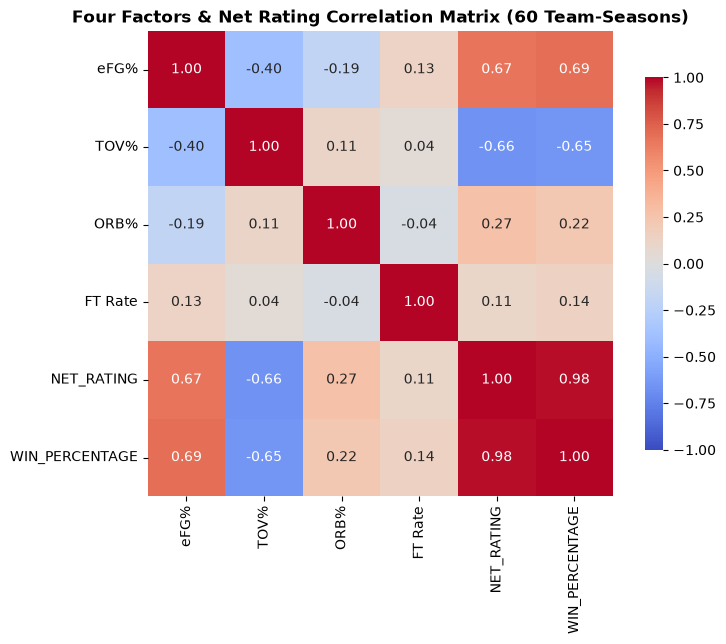

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6.5))
corr_cols = ['eFG%', 'TOV%', 'ORB%', 'FT Rate', 'NET_RATING', 'WIN_PERCENTAGE']
corr_matrix = games_regular_season_grouped[corr_cols].corr()
sns.heatmap(
    corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, 
    vmin=-1, vmax=1, square=True, cbar_kws={'shrink': 0.8}
)
plt.title('Four Factors & Net Rating Correlation Matrix (60 Team-Seasons)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

### 6c. Exploratory Visualization: Net Rating vs. Regular Season Win Percentage

We plot Net Rating against winning percentage to confirm the tight linear relationship ($R^2 \approx 0.94$) that underpins our team strength modeling.

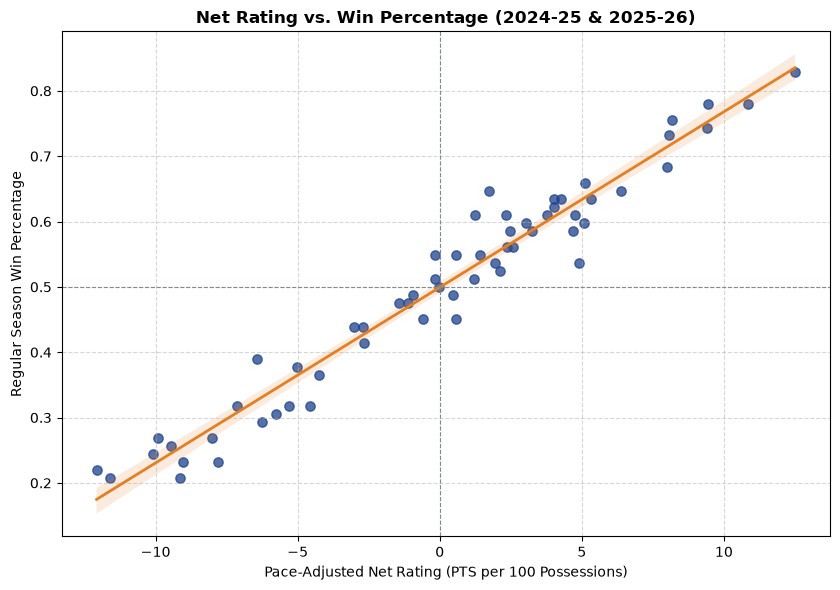

In [8]:
plt.figure(figsize=(8.5, 6))
sns.regplot(
    data=games_regular_season_grouped, x='NET_RATING', y='WIN_PERCENTAGE',
    scatter_kws={'alpha': 0.75, 'color': '#1D428A', 's': 45},
    line_kws={'color': '#E67E22', 'linewidth': 2}
)
plt.axhline(0.5, color='#7F8C8D', linestyle='--', linewidth=0.8)
plt.axvline(0.0, color='#7F8C8D', linestyle='--', linewidth=0.8)
plt.title('Net Rating vs. Win Percentage (2024-25 & 2025-26)', fontsize=12, fontweight='bold')
plt.xlabel('Pace-Adjusted Net Rating (PTS per 100 Possessions)')
plt.ylabel('Regular Season Win Percentage')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 7. MVP Shares + All-NBA Team Presence

**Question:** How much individual star power and award recognition does 
each team carry into a season?

MVP voting share and All-NBA selections are strong proxies for 
top-end talent — a factor that raw box score stats alone can 
undercount, since award voting captures reputation, "eye test" 
impact, and team success together.



In [9]:
# load the manually compiled CSVs 
mvp_shares = pd.read_csv(PROJECT_ROOT / 'data' / 'raw' / 'mvp_shares.csv')
all_nba = pd.read_csv(PROJECT_ROOT / 'data' / 'raw' / 'all_nba.csv')

In [10]:
# aggregating mvp_shares to team-season level - summing mvp_share per SEASON + TEAM in case multiple players from the same team made the MVP voting list
mvp_shares_team = mvp_shares.groupby(['season', 'team']).agg({
    'mvp_share': 'sum'
}).reset_index()

# aggregating all_nba to team-season level - counting how many players per SEASON + TEAM appear in the ALL-NBA list, and separately sum all_nba_share as a weighted version of the same signal
all_nba_team = all_nba.groupby(['season', 'team']).agg(
    ALL_NBA_COUNT=('player_name', 'count'),
    ALL_NBA_SHARE_SUM=('all_nba_share', 'sum')
).reset_index()

# merging mvp_shares_team onto games_regular_season_grouped
games_regular_season_grouped = pd.merge(
    games_regular_season_grouped, 
    mvp_shares_team, 
    left_on=['SEASON_LABEL', 'TEAM_ABBREVIATION'], 
    right_on=['season', 'team'], 
    how='left'
)

# merging all_nba_team onto games_regular_season_grouped
games_regular_season_grouped = pd.merge(
    games_regular_season_grouped, 
    all_nba_team, 
    left_on=['SEASON_LABEL', 'TEAM_ABBREVIATION'], 
    right_on=['season', 'team'], 
    how='left'
)

games_regular_season_grouped = games_regular_season_grouped.drop(columns=['season_x', 'team_x', 'season_y', 'team_y'])

# filling NaN values with 0 - a team with no mvp votes or no all-nba players
games_regular_season_grouped['mvp_share'] = games_regular_season_grouped['mvp_share'].fillna(0)
games_regular_season_grouped['ALL_NBA_COUNT'] = games_regular_season_grouped['ALL_NBA_COUNT'].fillna(0)
games_regular_season_grouped['ALL_NBA_SHARE_SUM'] = games_regular_season_grouped['ALL_NBA_SHARE_SUM'].fillna(0)

print("Shape of the grouped dataframe with four factors, net rating, and MVP/All-NBA data:", games_regular_season_grouped.shape)
display(games_regular_season_grouped.head(10))


Shape of the grouped dataframe with four factors, net rating, and MVP/All-NBA data: (60, 13)


,SEASON_LABEL,TEAM_ABBREVIATION,WIN,GAME_ID,WIN_PERCENTAGE,eFG%,TOV%,ORB%,FT Rate,NET_RATING,mvp_share,ALL_NBA_COUNT,ALL_NBA_SHARE_SUM
0,2024-25,ATL,40,82,0.487805,0.547733,0.126258,0.260635,0.198276,-0.958159,0.000,0.0,0.000
1,2024-25,BKN,26,82,0.317073,0.517414,0.127060,0.242355,0.190842,-7.125251,0.000,0.0,0.000
2,2024-25,BOS,61,82,0.743902,0.561858,0.103155,0.255842,0.170975,9.397202,0.311,1.0,1.000
3,2024-25,CHA,19,82,0.231707,0.503948,0.132114,0.264301,0.175867,-9.050762,0.000,0.0,0.000
4,2024-25,CHI,39,82,0.475610,0.554492,0.121329,0.222886,0.175299,-1.438779,0.000,0.0,0.000
5,2024-25,CLE,64,82,0.780488,0.578973,0.110769,0.258348,0.189829,9.442753,0.075,2.0,1.304
6,2024-25,DAL,39,82,0.475610,0.550836,0.119703,0.234250,0.205392,-1.107044,0.000,0.0,0.000
7,2024-25,DEN,50,82,0.609756,0.574615,0.119232,0.266557,0.202515,3.758321,0.787,1.0,1.000
8,2024-25,DET,44,82,0.536585,0.548781,0.124178,0.259457,0.194834,1.934339,0.012,1.0,0.446
9,2024-25,GSW,48,82,0.585366,0.537070,0.116519,0.271509,0.189377,3.262096,0.002,1.0,0.488


**Takeaway:** MVP shares and All-NBA presence were successfully merged 
onto the team-season table, with teams carrying no award recognition 
correctly filled to 0 rather than left as missing values. Teams with 
known star talent (e.g. reigning MVP-caliber players) show non-zero 
values as expected.

## 8. Playoff Depth (Round Reached)

**Question:** How far did each team actually advance in the playoffs 
each season?

Since the raw data has no explicit round label, we derive it from the 
number of distinct playoff opponents (series) a team faced, ordered 
chronologically — round 1 series happen before round 2, and so on. 
We also separately flag whether a team won the championship, since 
"reached the Finals" and "won the Finals" are different outcomes.

In [11]:
# filtering games_combined to playoff games only
playoff_games = games_combined[games_combined['SEASON_TYPE_LABEL'] == 'Playoffs'].copy()

# creating a win column from the playoff_games
playoff_games['WIN'] = playoff_games['WL'].apply(lambda x: 1 if x == 'W' else 0)

# each team's opponent per game, using the matchup column
def get_opponent(row):
    teams_in_matchup = row['MATCHUP'].replace('@', 'vs.').split(' vs. ')
    teams_in_matchup = [t.strip() for t in teams_in_matchup]
    return [t for t in teams_in_matchup if t != row['TEAM_ABBREVIATION']][0]

playoff_games['OPPONENT'] = playoff_games.apply(get_opponent, axis=1)

# grouping by season_label and team abb to identify each distinct playoff series to order series chronologically and count wins within that series
series_summary = playoff_games.groupby(['SEASON_LABEL', 'TEAM_ABBREVIATION', 'OPPONENT']).agg(
    SERIES_START_DATE=('GAME_DATE', 'min'),
    SERIES_WIN=('WIN', 'sum'),
    SERIES_GAMES=('GAME_ID', 'count')
).reset_index()

# WON SERIES LOGIC
series_summary['WON_SERIES'] = series_summary['SERIES_WIN'] > (series_summary['SERIES_GAMES'] / 2)

# ranking series chronologically within each season
series_summary['ROUND_NUMBER'] = series_summary.groupby(['SEASON_LABEL', 'TEAM_ABBREVIATION'])['SERIES_START_DATE'].rank(method='first').astype(int)

# team-season furthest series (win or lose)
playoff_depth = series_summary.groupby(['SEASON_LABEL', 'TEAM_ABBREVIATION']).agg(
    PLAYOFF_ROUND_REACHED=('ROUND_NUMBER', 'max')
).reset_index()

# a team is champion if they reached the furthest round (4) and won that series
finals_results = series_summary[series_summary['ROUND_NUMBER'] == 4][['SEASON_LABEL', 'TEAM_ABBREVIATION', 'WON_SERIES']]
finals_results = finals_results.rename(columns={'WON_SERIES': 'WON_CHAMPIONSHIP'})

playoff_depth = pd.merge(
    playoff_depth, 
    finals_results, 
    on=['SEASON_LABEL', 'TEAM_ABBREVIATION'], 
    how='left'
)
playoff_depth['WON_CHAMPIONSHIP'] = playoff_depth['WON_CHAMPIONSHIP'].fillna(False)

display(playoff_depth.head(30))

,SEASON_LABEL,TEAM_ABBREVIATION,PLAYOFF_ROUND_REACHED,WON_CHAMPIONSHIP
0,2024-25,BOS,2,False
1,2024-25,CLE,2,False
2,2024-25,DEN,2,False
3,2024-25,DET,1,False
4,2024-25,GSW,2,False
5,2024-25,HOU,1,False
6,2024-25,IND,4,False
7,2024-25,LAC,1,False
8,2024-25,LAL,1,False
9,2024-25,MEM,1,False


In [12]:
# merging playoff_depth onto games_regular_season_grouped filling 0 (no playoff appearance) and False (no championship win)
games_regular_season_grouped = pd.merge(
    games_regular_season_grouped, 
    playoff_depth, 
    on=['SEASON_LABEL', 'TEAM_ABBREVIATION'], 
    how='left'
)
games_regular_season_grouped['PLAYOFF_ROUND_REACHED'] = games_regular_season_grouped['PLAYOFF_ROUND_REACHED'].fillna(0).astype(int)
games_regular_season_grouped['WON_CHAMPIONSHIP'] = games_regular_season_grouped['WON_CHAMPIONSHIP'].fillna(False)

display(games_regular_season_grouped.head(10))

,SEASON_LABEL,TEAM_ABBREVIATION,WIN,GAME_ID,WIN_PERCENTAGE,eFG%,TOV%,ORB%,FT Rate,NET_RATING,mvp_share,ALL_NBA_COUNT,ALL_NBA_SHARE_SUM,PLAYOFF_ROUND_REACHED,WON_CHAMPIONSHIP
0,2024-25,ATL,40,82,0.487805,0.547733,0.126258,0.260635,0.198276,-0.958159,0.000,0.0,0.000,0,False
1,2024-25,BKN,26,82,0.317073,0.517414,0.127060,0.242355,0.190842,-7.125251,0.000,0.0,0.000,0,False
2,2024-25,BOS,61,82,0.743902,0.561858,0.103155,0.255842,0.170975,9.397202,0.311,1.0,1.000,2,False
3,2024-25,CHA,19,82,0.231707,0.503948,0.132114,0.264301,0.175867,-9.050762,0.000,0.0,0.000,0,False
4,2024-25,CHI,39,82,0.475610,0.554492,0.121329,0.222886,0.175299,-1.438779,0.000,0.0,0.000,0,False
5,2024-25,CLE,64,82,0.780488,0.578973,0.110769,0.258348,0.189829,9.442753,0.075,2.0,1.304,2,False
6,2024-25,DAL,39,82,0.475610,0.550836,0.119703,0.234250,0.205392,-1.107044,0.000,0.0,0.000,0,False
7,2024-25,DEN,50,82,0.609756,0.574615,0.119232,0.266557,0.202515,3.758321,0.787,1.0,1.000,2,False
8,2024-25,DET,44,82,0.536585,0.548781,0.124178,0.259457,0.194834,1.934339,0.012,1.0,0.446,1,False
9,2024-25,GSW,48,82,0.585366,0.537070,0.116519,0.271509,0.189377,3.262096,0.002,1.0,0.488,2,False


**Takeaway:** Playoff round reached and championship status were 
derived from chronologically ordered playoff series per team, since 
the raw data has no explicit round label. Spot-checking 2024-25 
against known results confirms the derivation is accurate.

## 9. Playoff Experience

**Question:** What does each team's current (2026-27) roster look like, 
so we can attribute playoff experience to where players are now rather 
than where they played it?

We pull live current rosters via `nba_api`'s `CommonTeamRoster` endpoint 
for all 30 teams, since players who changed teams should carry their 
playoff experience to their new team, not leave it behind with their 
old one.

In [13]:
if ROSTER_CACHE_PATH.exists() and not REFRESH_API:
    phi_roster_df = pd.read_csv(ROSTER_CACHE_PATH).query('TeamID == 1610612755')
else:
    phi_roster = commonteamroster.CommonTeamRoster(team_id=1610612755, season='2026-27')
    phi_roster_df = phi_roster.get_data_frames()[0]
display(phi_roster_df.head(15))

,TeamID,SEASON,LeagueID,PLAYER,NICKNAME,PLAYER_SLUG,NUM,POSITION,HEIGHT,WEIGHT,BIRTH_DATE,AGE,EXP,SCHOOL,PLAYER_ID,HOW_ACQUIRED,SUPPLEMENTAL_STATUS
313,1610612755,2026,0,Tyrese Maxey,Tyrese,tyrese-maxey,0.0,G,6-2,200.0,"NOV 04, 2000",25.0,6,Kentucky,1630178,#21 Pick in 2020 Draft,0
314,1610612755,2026,0,Labaron Philon Jr.,Labaron,labaron-philon-jr,0.0,G,6-3,177.0,"NOV 24, 2005",20.0,R,Alabama,1642889,#22 Pick in 2026 Draft,0
315,1610612755,2026,0,Kentavious Caldwell-Pope,Kentavious,kentavious-caldwell-pope,1.0,G,6-5,204.0,"FEB 18, 1993",33.0,13,Georgia,203484,Signed on 08/05/26,0
316,1610612755,2026,0,Caleb Love,Caleb,caleb-love,2.0,G,6-3,212.0,"SEP 27, 2001",25.0,1,Arizona,1631126,Signed on 07/05/26,1
317,1610612755,2026,0,Anfernee Simons,Anfernee,anfernee-simons,5.0,G,6-4,200.0,"JUN 08, 1999",27.0,8,Edgewater HS (FL),1629014,Signed on 07/06/26,0
318,1610612755,2026,0,Jaylen Brown,Jaylen,jaylen-brown,7.0,G-F,6-6,223.0,"OCT 24, 1996",29.0,10,California,1627759,Traded from BOS on 07/06/26,0
319,1610612755,2026,0,Justin Edwards,Justin,justin-edwards,11.0,F,6-7,217.0,"DEC 16, 2003",22.0,2,Kentucky,1642348,Signed on 07/04/24,0
320,1610612755,2026,0,Rayan Rupert,Rayan,rayan-rupert,12.0,G-F,6-7,205.0,"MAY 31, 2004",22.0,3,New Zealand Breakers,1641712,Signed on 07/08/26,1
321,1610612755,2026,0,Joel Embiid,Joel,joel-embiid,21.0,C-F,7-0,270.0,"MAR 16, 1994",32.0,10,Kansas,203954,#3 Pick in 2014 Draft,0
322,1610612755,2026,0,LeBron James,LeBron,lebron-james,23.0,F,6-9,250.0,"DEC 30, 1984",41.0,23,St. Vincent-St. Mary HS (OH),2544,Signed on 07/26/26,0


In [14]:
all_teams = teams.get_teams()
all_teams_df = pd.DataFrame(all_teams)
display(all_teams_df.head(30))

,id,full_name,abbreviation,nickname,city,state,year_founded
0,1610612737,Atlanta Hawks,ATL,Hawks,Atlanta,Georgia,1949
1,1610612738,Boston Celtics,BOS,Celtics,Boston,Massachusetts,1946
2,1610612739,Cleveland Cavaliers,CLE,Cavaliers,Cleveland,Ohio,1970
3,1610612740,New Orleans Pelicans,NOP,Pelicans,New Orleans,Louisiana,2002
4,1610612741,Chicago Bulls,CHI,Bulls,Chicago,Illinois,1966
5,1610612742,Dallas Mavericks,DAL,Mavericks,Dallas,Texas,1980
6,1610612743,Denver Nuggets,DEN,Nuggets,Denver,Colorado,1976
7,1610612744,Golden State Warriors,GSW,Warriors,San Francisco,California,1946
8,1610612745,Houston Rockets,HOU,Rockets,Houston,Texas,1967
9,1610612746,Los Angeles Clippers,LAC,Clippers,Los Angeles,California,1970


In [15]:
if ROSTER_CACHE_PATH.exists() and not REFRESH_API:
    rosters_combined = pd.read_csv(ROSTER_CACHE_PATH)
    print(f"Loaded cached 2026-27 rosters ({SNAPSHOT_TAG}): {ROSTER_CACHE_PATH.name}")
else:
    all_rosters = []
    for team_id in all_teams_df['id']:
        roster = commonteamroster.CommonTeamRoster(team_id=team_id, season='2026-27')
        roster_df = roster.get_data_frames()[0]
        all_rosters.append(roster_df)
        time.sleep(1)  # to avoid hitting the API rate limit
    rosters_combined = pd.concat(all_rosters, ignore_index=True)
    ROSTER_CACHE_PATH.parent.mkdir(parents=True, exist_ok=True)
    rosters_combined.to_csv(ROSTER_CACHE_PATH, index=False)
    print(f"Fetched live 2026-27 rosters and cached to: {ROSTER_CACHE_PATH.name}")

display(rosters_combined.shape)
display(rosters_combined.head())

Loaded cached 2026-27 rosters (opening_week_oct2026): rosters_26_27_opening_week_oct2026.csv


(519, 17)

,TeamID,SEASON,LeagueID,PLAYER,NICKNAME,PLAYER_SLUG,NUM,POSITION,HEIGHT,WEIGHT,BIRTH_DATE,AGE,EXP,SCHOOL,PLAYER_ID,HOW_ACQUIRED,SUPPLEMENTAL_STATUS
0,1610612737,2026,0,Luguentz Dort,Luguentz,luguentz-dort,0.0,G,6-4,220.0,"APR 19, 1999",27.0,7,Arizona State,1629652,Traded from OKC on 07/19/26,0
1,1610612737,2026,0,RayJ Dennis,RayJ,rayj-dennis,0.0,G,6-1,180.0,"MAR 30, 2001",25.0,2,Baylor,1642484,Signed on 12/31/25,1
2,1610612737,2026,0,Keshon Gilbert,Keshon,keshon-gilbert,0.0,G,6-3,200.0,"JUN 30, 2003",23.0,1,Iowa State,1642933,Signed on 03/04/26,1
3,1610612737,2026,0,Jalen Johnson,Jalen,jalen-johnson,1.0,F,6-8,219.0,"DEC 18, 2001",24.0,5,Duke,1630552,#20 Pick in 2021 Draft,0
4,1610612737,2026,0,Aaron Wiggins,Aaron,aaron-wiggins,2.0,G,6-5,190.0,"JAN 02, 1999",27.0,5,Maryland,1630598,Traded from OKC on 07/06/26,0


**Question:** How much playoff-tested experience does each team's 
current roster carry, based on games played across 2024-25 and 2025-26?

Since players move between teams, this feature attributes cumulative 
playoff games to a player's *current* (2026-27) roster spot, not 
necessarily the team they played those playoff games for originally.

In [16]:
# pulling playoff games at the player level for both 24-25 and 25-26 seasons (cached in data/raw)
if PLAYER_PLAYOFF_CACHE_PATH.exists() and not REFRESH_API:
    playoff_player_games_combined = pd.read_csv(PLAYER_PLAYOFF_CACHE_PATH, dtype={'GAME_ID': str})
    print(f"Loaded cached playoff player logs: {PLAYER_PLAYOFF_CACHE_PATH.name}")
else:
    playoff_player_games = []
    for season in ['2024-25', '2025-26']:
        gf = leaguegamefinder.LeagueGameFinder(
            season_nullable=season,
            season_type_nullable='Playoffs',
            player_or_team_abbreviation='P'
        )
        df = gf.get_data_frames()[0]
        df['SEASON_LABEL'] = season
        playoff_player_games.append(df)
        time.sleep(1)  # to avoid hitting the API rate limit
    playoff_player_games_combined = pd.concat(playoff_player_games, ignore_index=True)
    PLAYER_PLAYOFF_CACHE_PATH.parent.mkdir(parents=True, exist_ok=True)
    playoff_player_games_combined.to_csv(PLAYER_PLAYOFF_CACHE_PATH, index=False)
    print(f"Fetched playoff player logs and cached to: {PLAYER_PLAYOFF_CACHE_PATH.name}")

display(playoff_player_games_combined.shape)
display(playoff_player_games_combined.head())

Loaded cached playoff player logs: player_playoff_games_24_26.csv


(3725, 31)

,SEASON_ID,PLAYER_ID,PLAYER_NAME,TEAM_ID,TEAM_ABBREVIATION,TEAM_NAME,GAME_ID,GAME_DATE,MATCHUP,WL,...,OREB,DREB,REB,AST,STL,BLK,TOV,PF,PLUS_MINUS,SEASON_LABEL
0,42024,1626167,Myles Turner,1610612754,IND,Indiana Pacers,0042400407,2025-06-22,IND @ OKC,L,...,1,3,4,1,0,0,1,3,-12,2024-25
1,42024,1628392,Isaiah Hartenstein,1610612760,OKC,Oklahoma City Thunder,0042400407,2025-06-22,OKC vs. IND,W,...,3,6,9,4,1,0,2,0,1,2024-25
2,42024,1628418,Thomas Bryant,1610612754,IND,Indiana Pacers,0042400407,2025-06-22,IND @ OKC,L,...,0,0,0,0,0,0,0,0,2,2024-25
3,42024,1642277,Johnny Furphy,1610612754,IND,Indiana Pacers,0042400407,2025-06-22,IND @ OKC,L,...,0,0,0,0,0,0,0,0,4,2024-25
4,42024,1631172,Ousmane Dieng,1610612760,OKC,Oklahoma City Thunder,0042400407,2025-06-22,OKC vs. IND,W,...,0,0,0,0,0,0,0,0,-4,2024-25


With player-level playoff games pulled for both seasons, we now sum 
each player's total games played across 2024-25 and 2025-26 combined.

In [17]:
# counting each player's total playoff games across both seasons combined
player_playoff_experience = playoff_player_games_combined.groupby(['PLAYER_ID', 'PLAYER_NAME']).agg(
    PLAYOFF_GAMES_PLAYED=('GAME_ID', 'count')
).reset_index()

display(player_playoff_experience.sort_values('PLAYOFF_GAMES_PLAYED', ascending=False).head(10))

,PLAYER_ID,PLAYER_NAME,PLAYOFF_GAMES_PLAYED
271,1641717,Cason Wallace,38
226,1631096,Chet Holmgren,38
113,1628983,Shai Gilgeous-Alexander,38
152,1629652,Luguentz Dort,38
94,1628392,Isaiah Hartenstein,38
85,1627936,Alex Caruso,38
193,1630540,Miles McBride,37
107,1628969,Mikal Bridges,37
98,1628404,Josh Hart,37
109,1628973,Jalen Brunson,37


Now we attribute each player's cumulative playoff total to their 
*current* team, by joining this onto the live roster pull rather than 
their original playoff team — capturing the effect of trades and 
free agency moves.

In [18]:
# attributing this experience to each player's current (2026-27) team
roster_with_experience = pd.merge(
    rosters_combined, 
    player_playoff_experience, 
    on='PLAYER_ID',
    how='left'
)

# players w/ no playoff games in the last 2 seasons filling NaN with 0
roster_with_experience['PLAYOFF_GAMES_PLAYED'] = roster_with_experience['PLAYOFF_GAMES_PLAYED'].fillna(0)

display(roster_with_experience.head())

,TeamID,SEASON,LeagueID,PLAYER,NICKNAME,PLAYER_SLUG,NUM,POSITION,HEIGHT,WEIGHT,BIRTH_DATE,AGE,EXP,SCHOOL,PLAYER_ID,HOW_ACQUIRED,SUPPLEMENTAL_STATUS,PLAYER_NAME,PLAYOFF_GAMES_PLAYED
0,1610612737,2026,0,Luguentz Dort,Luguentz,luguentz-dort,0.0,G,6-4,220.0,"APR 19, 1999",27.0,7,Arizona State,1629652,Traded from OKC on 07/19/26,0,Luguentz Dort,38.0
1,1610612737,2026,0,RayJ Dennis,RayJ,rayj-dennis,0.0,G,6-1,180.0,"MAR 30, 2001",25.0,2,Baylor,1642484,Signed on 12/31/25,1,NaN,0.0
2,1610612737,2026,0,Keshon Gilbert,Keshon,keshon-gilbert,0.0,G,6-3,200.0,"JUN 30, 2003",23.0,1,Iowa State,1642933,Signed on 03/04/26,1,NaN,0.0
3,1610612737,2026,0,Jalen Johnson,Jalen,jalen-johnson,1.0,F,6-8,219.0,"DEC 18, 2001",24.0,5,Duke,1630552,#20 Pick in 2021 Draft,0,Jalen Johnson,6.0
4,1610612737,2026,0,Aaron Wiggins,Aaron,aaron-wiggins,2.0,G,6-5,190.0,"JAN 02, 1999",27.0,5,Maryland,1630598,Traded from OKC on 07/06/26,0,Aaron Wiggins,35.0


Finally, we sum playoff experience across each team's full current 
roster, producing one cumulative total per team.

In [19]:
# summing playoff exp per team to get the team-level 
team_playoff_experience = roster_with_experience.groupby('TeamID').agg(
    TOTAL_PLAYOFF_EXPERIENCE=('PLAYOFF_GAMES_PLAYED', 'sum')
).reset_index()

display(team_playoff_experience.sort_values('TOTAL_PLAYOFF_EXPERIENCE', ascending=False).head(10))

,TeamID,TOTAL_PLAYOFF_EXPERIENCE
23,1610612760,324.0
15,1610612752,323.0
22,1610612759,264.0
2,1610612739,218.0
17,1610612754,207.0
1,1610612738,196.0
28,1610612765,186.0
13,1610612750,166.0
18,1610612755,141.0
0,1610612737,141.0


In [20]:
# mapping TeamID to TEAM_ABBREVIATION using all_teams_df
team_id_to_abbrev = all_teams_df[['id', 'abbreviation']].rename(columns={'id': 'TeamID', 'abbreviation': 'TEAM_ABBREVIATION'})

team_playoff_experience = pd.merge(
    team_playoff_experience, 
    team_id_to_abbrev,
    on='TeamID',
    how='left'
)

display(team_playoff_experience.sort_values('TOTAL_PLAYOFF_EXPERIENCE', ascending=False).head(10))

,TeamID,TOTAL_PLAYOFF_EXPERIENCE,TEAM_ABBREVIATION
23,1610612760,324.0,OKC
15,1610612752,323.0,NYK
22,1610612759,264.0,SAS
2,1610612739,218.0,CLE
17,1610612754,207.0,IND
1,1610612738,196.0,BOS
28,1610612765,186.0,DET
13,1610612750,166.0,MIN
18,1610612755,141.0,PHI
0,1610612737,141.0,ATL


In [21]:
# single current-roster snapshot (2026-27)
team_playoff_experience_final = team_playoff_experience[['TEAM_ABBREVIATION', 'TOTAL_PLAYOFF_EXPERIENCE']]

display(team_playoff_experience_final)

,TEAM_ABBREVIATION,TOTAL_PLAYOFF_EXPERIENCE
0,ATL,141.0
1,BOS,196.0
2,CLE,218.0
3,NOP,36.0
4,CHI,33.0
5,DAL,15.0
6,DEN,118.0
7,GSW,98.0
8,HOU,107.0
9,LAC,90.0


**Takeaway:** Playoff experience totals align with expectations — teams 
that made deep 2024-25/2025-26 playoff runs (OKC, New York, San Antonio, Cleveland, Indiana) 
show the highest cumulative totals on their 2026-27 Opening-Week rosters, correctly 
carrying traded and free-agent players' playoff history to their current team (e.g. Luguentz Dort's 
and Aaron Wiggins' OKC playoff games now count toward Atlanta). Because this feature is a 
2026-27 roster snapshot (`SNAPSHOT_TAG = 'opening_week_oct2026'`) rather than a historical 
team-season stat, it is saved separately as `playoff_experience_snapshot.csv` for Phase 4.

In [22]:
# saving both outputs for Phases 3 & 4
games_regular_season_grouped.to_csv(PROJECT_ROOT / 'data' / 'processed' / 'team_season_features.csv', index=False)
team_playoff_experience_final.to_csv(PROJECT_ROOT / 'data' / 'processed' / 'playoff_experience_snapshot.csv', index=False)

## 10. Player Valuation Aggregation (Game Score + Minutes Scale)

**Question:** Can we estimate each player's individual value using their 
own box score performance, then attribute that value to their current 
(2026-27) team — capturing real roster changes instead of relying on 
purely historical, franchise-level stats?

We use **John Hollinger's Game Score (`GmSc`)** weighted by starter-scale workload (`AVG_MIN / 36.0`) — combining scoring volume, shooting efficiency (penalizing missed field goals and free throws), playmaking, rebounding, defensive events (steals, blocks), and ball security (penalizing turnovers and fouls), while naturally discounting low-minute bench bursts. Filtered to players with a meaningful sample size (`>= 20` games) and aggregated across each team's top-9 rotation players above replacement (`REPLACEMENT_LEVEL = 3.0`).


In [23]:
# pulling player-level regular season games for both seasons (cached in data/raw)
if PLAYER_REGULAR_CACHE_PATH.exists() and not REFRESH_API:
    player_games_combined = pd.read_csv(PLAYER_REGULAR_CACHE_PATH, dtype={'GAME_ID': str})
    print(f"Loaded cached regular-season player logs: {PLAYER_REGULAR_CACHE_PATH.name}")
else:
    player_games = []
    for season in ['2024-25', '2025-26']:
        gf = leaguegamefinder.LeagueGameFinder(
            season_nullable=season,
            season_type_nullable='Regular Season',
            player_or_team_abbreviation='P'
        )
        df = gf.get_data_frames()[0]
        df['SEASON_LABEL'] = season
        player_games.append(df)
        time.sleep(1)
    player_games_combined = pd.concat(player_games, ignore_index=True)
    PLAYER_REGULAR_CACHE_PATH.parent.mkdir(parents=True, exist_ok=True)
    player_games_combined.to_csv(PLAYER_REGULAR_CACHE_PATH, index=False)
    print(f"Fetched regular-season player logs and cached to: {PLAYER_REGULAR_CACHE_PATH.name}")

display(player_games_combined.shape)

Loaded cached regular-season player logs: player_regular_games_24_26.csv

(52957, 31)

In [24]:
player_value = player_games_combined.groupby(['PLAYER_ID', 'PLAYER_NAME']).agg(
    GAMES_PLAYED=('GAME_ID', 'count'),
    AVG_MIN=('MIN', 'mean'), # Crucial for our minutes multiplier
    AVG_PTS=('PTS', 'mean'),
    AVG_FGM=('FGM', 'mean'),
    AVG_FGA=('FGA', 'mean'),
    AVG_FTM=('FTM', 'mean'),
    AVG_FTA=('FTA', 'mean'),
    AVG_OREB=('OREB', 'mean'),
    AVG_DREB=('DREB', 'mean'),
    AVG_AST=('AST', 'mean'),
    AVG_STL=('STL', 'mean'),
    AVG_BLK=('BLK', 'mean'),
    AVG_TOV=('TOV', 'mean'),
    AVG_PF=('PF', 'mean')
).reset_index()

# ---------------------------------------------------------
# Calculate John Hollinger's Game Score (GmSc)
# Formula penalizes inefficiency: missed shots, missed FTs, fouls, turnovers
# ---------------------------------------------------------
player_value['RAW_GmSc'] = (
    player_value['AVG_PTS'] + 
    (0.4 * player_value['AVG_FGM']) - 
    (0.7 * player_value['AVG_FGA']) - 
    (0.4 * (player_value['AVG_FTA'] - player_value['AVG_FTM'])) + 
    (0.7 * player_value['AVG_OREB']) + 
    (0.3 * player_value['AVG_DREB']) + 
    player_value['AVG_STL'] + 
    (0.7 * player_value['AVG_AST']) + 
    (0.7 * player_value['AVG_BLK']) - 
    (0.4 * player_value['AVG_PF']) - 
    player_value['AVG_TOV']
)

# ---------------------------------------------------------
# Apply Minutes Weighting
# Scales raw Game Score down if a player doesn't play starter minutes
# ---------------------------------------------------------
player_value['MINUTES_WEIGHT'] = player_value['AVG_MIN'] / 36.0
player_value['PLAYER_VALUE'] = player_value['RAW_GmSc'] * player_value['MINUTES_WEIGHT']

# ---------------------------------------------------------
# Empirical Bayesian Shrinkage (Regression to the Mean)
# Instead of hard-filtering < 20 games (which zeroes out injured stars),
# we apply shrinkage with K = 8.0 games (derived from split-half reliability r = 0.981)
# toward replacement level (REPLACEMENT_LEVEL = 3.90).
# ---------------------------------------------------------
K_PARAM = 8.0
REPLACEMENT_LEVEL = 3.90

player_value_clean = player_value.drop(columns=['PLAYER_NAME'])

roster_with_value_filtered = pd.merge(
    rosters_combined,
    player_value_clean,
    on='PLAYER_ID',
    how='left'
)

# Apply shrinkage to players with historical games
has_games = (roster_with_value_filtered['GAMES_PLAYED'] > 0) & (~roster_with_value_filtered['PLAYER_VALUE'].isna())
roster_with_value_filtered.loc[has_games, 'SHRUNK_VALUE'] = (
    roster_with_value_filtered.loc[has_games, 'GAMES_PLAYED'] * roster_with_value_filtered.loc[has_games, 'PLAYER_VALUE'] + K_PARAM * REPLACEMENT_LEVEL
) / (roster_with_value_filtered.loc[has_games, 'GAMES_PLAYED'] + K_PARAM)

# Display the top 15 highest valued individual players in the league
display(roster_with_value_filtered[has_games].sort_values('SHRUNK_VALUE', ascending=False)[['PLAYER', 'TeamID', 'GAMES_PLAYED', 'AVG_MIN', 'PLAYER_VALUE', 'SHRUNK_VALUE']].head(15))


,PLAYER,TeamID,GAMES_PLAYED,AVG_MIN,PLAYER_VALUE,SHRUNK_VALUE
116,Nikola Jokić,1610612743,135.0,35.851852,29.301881,27.880797
397,Shai Gilgeous-Alexander,1610612760,144.0,33.729167,25.081513,23.966697
192,Luka Dončić,1610612747,114.0,35.605263,24.410080,23.065157
197,Giannis Antetokounmpo,1610612748,103.0,32.330097,22.882176,21.514091
313,Tyrese Maxey,1610612755,122.0,37.918033,21.953091,20.842131
144,Kevin Durant,1610612745,140.0,36.492857,20.206472,19.325041
232,Anthony Edwards,1610612750,140.0,35.728571,19.798166,18.938805
18,Jayson Tatum,1610612738,88.0,35.738636,19.755524,18.434230
348,Damian Lillard,1610612757,58.0,36.103448,20.303002,18.314760
271,Jalen Brunson,1610612752,139.0,35.223022,19.000300,18.178515


## 11. Rookie Valuation (Empirically Measured Draft-Slot Priors)

**Question:** How do we assign value to incoming rookies who have zero historical NBA data, without arbitrarily guessing or unfairly punishing teams that rely heavily on recent lottery picks?

We extract each player's draft position from `HOW_ACQUIRED` and map it to **empirically measured median rookie-season production** calculated from the actual rookie seasons of 2024 and 2025 draftees:
- **Picks 1-3:** `6.60` (Top franchise draftees like Alex Sarr, Zaccharie Risacher, Cooper Flagg)
- **Picks 4-14 (Lottery):** `4.84` (Impact rotation rookies)
- **Picks 15-30 (Late 1st):** `2.80` (Bench rotation prospects)
- **Round 2 / Undrafted:** `1.05` (Developmental depth)


In [25]:
conditions = [
    roster_with_value_filtered['HOW_ACQUIRED'].str.contains(r'#(?:1|2|3)\b\s*Pick', case=False, na=False),
    roster_with_value_filtered['HOW_ACQUIRED'].str.contains(r'#(?:[4-9]|1[0-4])\b\s*Pick', case=False, na=False),
    roster_with_value_filtered['HOW_ACQUIRED'].str.contains(r'#(?:1[5-9]|2[0-9]|30)\b\s*Pick', case=False, na=False)
]

# Empirically measured rookie-season median values from 2024 & 2025 draftees
values = [6.60, 4.84, 2.80]

rookie_proj = np.select(conditions, values, default=1.05)

# applying the empirical prior only to rookies and players with no historical regular season games
no_games_mask = ~has_games
roster_with_value_filtered.loc[no_games_mask, 'SHRUNK_VALUE'] = rookie_proj[no_games_mask]

display(roster_with_value_filtered[no_games_mask][
    ['PLAYER', 'TeamID', 'HOW_ACQUIRED', 'SHRUNK_VALUE']
].sort_values('SHRUNK_VALUE', ascending=False).head(15))


,PLAYER,TeamID,HOW_ACQUIRED,SHRUNK_VALUE
442,Darryn Peterson,1610612762,#2 Pick in 2026 Draft,6.60
460,Cameron Boozer,1610612763,#3 Pick in 2026 Draft,6.60
469,AJ Dybantsa,1610612764,#1 Pick in 2026 Draft,6.60
123,Yaxel Lendeborg,1610612744,#11 Pick in 2026 Draft,4.84
157,Keaton Wagler,1610612746,#5 Pick in 2026 Draft,4.84
96,Morez Johnson Jr.,1610612742,#9 Pick in 2026 Draft,4.84
245,Mikel Brown Jr.,1610612751,#6 Pick in 2026 Draft,4.84
74,Caleb Wilson,1610612741,#4 Pick in 2026 Draft,4.84
6,Kingston Flemings,1610612737,#8 Pick in 2026 Draft,4.84
211,Brayden Burries,1610612749,#10 Pick in 2026 Draft,4.84


**Takeaway:** Teams with incoming rookie talent and redshirt lottery picks (`AJ Dybantsa`, `Darryn Peterson`, `Cameron Boozer`, etc.) no longer receive a mathematical `0` for those rotation spots. The roster valuation accurately reflects the baseline expected impact of recent draft picks entering the `2026-27` season.


In [26]:
# calculating value over replacement player (VORP) using empirical replacement level (3.90)
roster_with_value_filtered['VORP'] = (roster_with_value_filtered['SHRUNK_VALUE'] - REPLACEMENT_LEVEL).clip(lower=0)

# player level verification
print("--- TOP 15 INDIVIDUAL PLAYERS (VERIFICATION) ---")
display(roster_with_value_filtered[['PLAYER', 'TeamID', 'RAW_GmSc', 'AVG_MIN', 'SHRUNK_VALUE', 'VORP']]
        .sort_values('VORP', ascending=False)
        .head(15))

# rank the top 9 rotation players per team and sum
roster_with_value_filtered['TEAM_RANK'] = roster_with_value_filtered.groupby('TeamID')['VORP'].rank(ascending=False, method='first')
top_rotation_only = roster_with_value_filtered[roster_with_value_filtered['TEAM_RANK'] <= 9]

team_roster_value_v2 = top_rotation_only.groupby('TeamID').agg(
    TOTAL_ROSTER_VALUE=('VORP', 'sum')
).reset_index()

team_roster_value_v2 = pd.merge(
    team_roster_value_v2,
    team_id_to_abbrev,
    on='TeamID',
    how='left'
)

print("\n--- FINAL TEAM ROSTER VALUATION ---")
display(team_roster_value_v2.sort_values('TOTAL_ROSTER_VALUE', ascending=False))

team_roster_value_v2.to_csv(PROJECT_ROOT / 'data' / 'processed' / 'roster_value_snapshot.csv', index=False)


--- TOP 15 INDIVIDUAL PLAYERS (VERIFICATION) ---


,PLAYER,TeamID,RAW_GmSc,AVG_MIN,SHRUNK_VALUE,VORP
116,Nikola Jokić,1610612743,29.422963,35.851852,27.880797,23.980797
397,Shai Gilgeous-Alexander,1610612760,26.770139,33.729167,23.966697,20.066697
192,Luka Dončić,1610612747,24.680702,35.605263,23.065157,19.165157
197,Giannis Antetokounmpo,1610612748,25.479612,32.330097,21.514091,17.614091
313,Tyrese Maxey,1610612755,20.842623,37.918033,20.842131,16.942131
144,Kevin Durant,1610612745,19.933571,36.492857,19.325041,15.425041
232,Anthony Edwards,1610612750,19.948571,35.728571,18.938805,15.038805
18,Jayson Tatum,1610612738,19.900000,35.738636,18.434230,14.534230
348,Damian Lillard,1610612757,20.244828,36.103448,18.314760,14.414760
271,Jalen Brunson,1610612752,19.419424,35.223022,18.178515,14.278515



--- FINAL TEAM ROSTER VALUATION ---


,TeamID,TOTAL_ROSTER_VALUE,TEAM_ABBREVIATION
18,1610612755,68.502467,PHI
6,1610612743,67.807450,DEN
3,1610612740,55.211829,NOP
15,1610612752,55.065146,NYK
20,1610612757,54.900685,POR
8,1610612745,54.313447,HOU
16,1610612753,51.011499,ORL
22,1610612759,49.086517,SAS
17,1610612754,48.581107,IND
10,1610612747,48.155338,LAL


### 11b. Visualization: Top 15 Individual NBA Players by Rotation VORP Impact

We visualize the top 15 individual players in the league ranked by their projected 2026-27 Value Over Replacement Player (VORP), reflecting empirical Bayesian shrinkage toward replacement level.

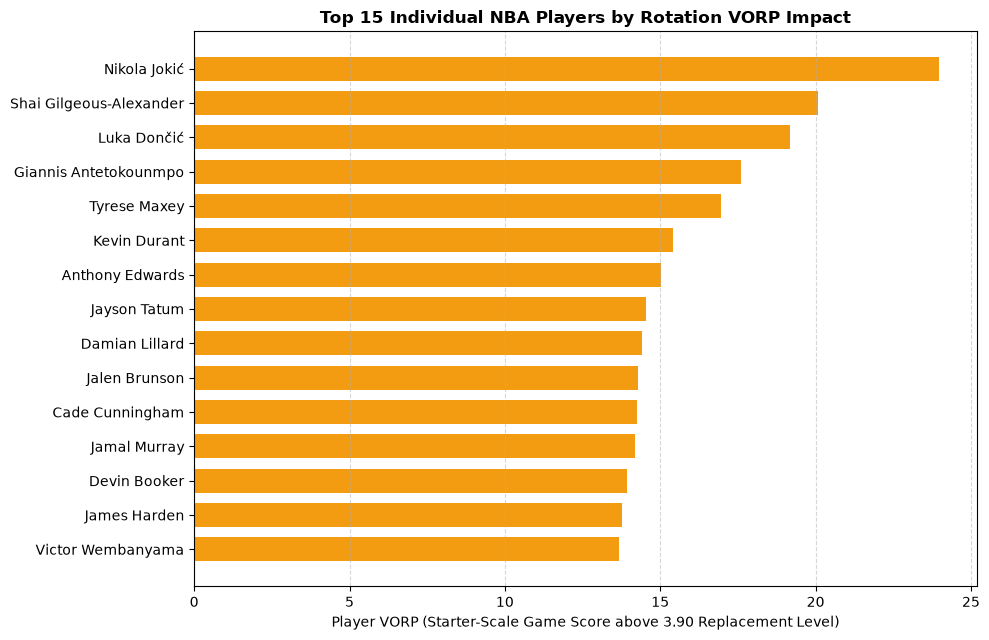

In [27]:
plt.figure(figsize=(10, 6.5))
top15_players = roster_with_value_filtered.sort_values('VORP', ascending=True).tail(15)
plt.barh(top15_players['PLAYER'], top15_players['VORP'], color='#F39C12', edgecolor='none', height=0.7)
plt.title('Top 15 Individual NBA Players by Rotation VORP Impact', fontsize=12, fontweight='bold')
plt.xlabel('Player VORP (Starter-Scale Game Score above 3.90 Replacement Level)')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 12. Phase 2 Summary

This notebook produced three processed feature tables (backed by reproducible raw snapshots in `data/raw/` under `SNAPSHOT_TAG = 'opening_week_oct2026'`):

1. **`team_season_features.csv`** (`games_regular_season_grouped`) — 60-row historical team-season table covering `2024-25` and `2025-26` (standings, Four Factors, Net Rating, MVP shares, All-NBA presence, and playoff depth), used in Phase 4's `70/30` historical team-efficiency projection and log-odds spread calibration (while Phase 3 computes leak-free rolling game-level Four Factors and Net Rating directly from `games_clean.csv`).
2. **`playoff_experience_snapshot.csv`** (`team_playoff_experience_final`) — 2026-27 Opening-Week roster snapshot of cumulative `2024-25` + `2025-26` playoff games played per team, carrying traded and free-agent players' postseason experience to their current roster.
3. **`roster_value_snapshot.csv`** (`team_roster_value_v2`) — 2026-27 Opening-Week roster valuation aggregating each team's Top-9 rotation players using workload-weighted Hollinger Game Score (`RAW_GmSc * AVG_MIN / 36.0`) with Empirical Bayesian Shrinkage ($K = 8.0$ games) above empirical replacement level (`REPLACEMENT_LEVEL = 3.90`) and data-driven draft-slot priors for incoming rookies.
